# Trabajo Final Integrador - Redes Neuronales 2026
### ***Autoencoder y clasificador convolucional de Fashion-MNIST con pre-entrenamiento***

---


# Objetivo general
Utilizando el conjunto de datos **Fashion-MNIST**, diseñe y evalúe un autoencoder convolucional profundo y estudie el efecto de utilizar su módulo codificador (encoder) como etapa de preentrenamiento para una red clasificadora convolucional.
El trabajo debe organizarse de modo que permita comparar, bajo un protocolo experimental coherente, distintas estrategias de inicialización y entrenamiento del codificador y del módulo clasificador.

# 1. Importamos Librerías

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms


import json
from pathlib import Path


# 2. Preparamos la tarjeta gráfica a utilizar

In [4]:
SEED = 100
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 2060 SUPER


# 3. Cargamos, preparamos y analizamos Fashion MNIST

In [5]:
transform = transforms.ToTensor()

full_train_set = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_set = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

split_generator = torch.Generator().manual_seed(SEED)

train_set, validation_set = random_split(
    full_train_set,
    [50_000, 10_000],
    generator=split_generator
)


print("------------------")
print("Train:", len(train_set))
print("Validation:", len(validation_set))
print("Test:", len(test_set))

------------------
Train: 50000
Validation: 10000
Test: 10000


# 3.1 Preparamos las clases

In [6]:
class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}

## 3.2 Mostramos algunas imágenes

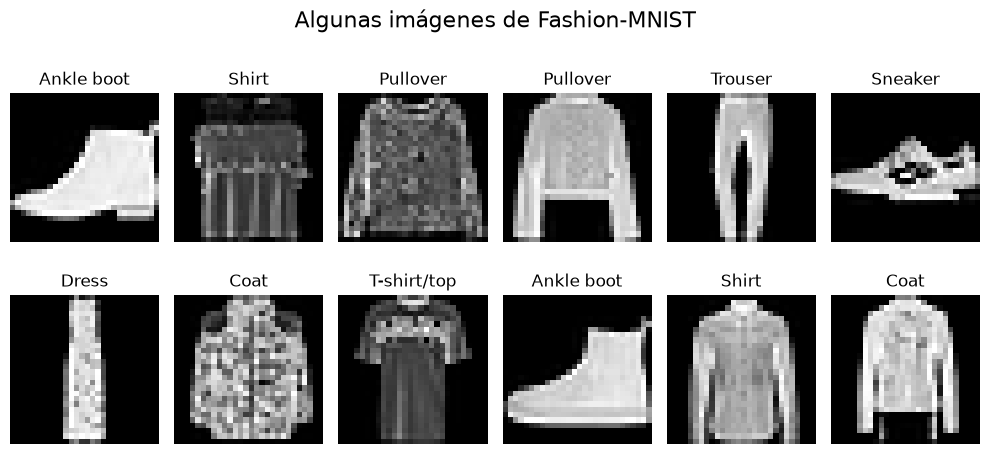

In [67]:
def imshow(img):
    plt.imshow(img.squeeze(), cmap="gray", vmin=0, vmax=1)
    plt.axis("off")
    plt.show()


display_generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(len(train_set), generator=display_generator)[:12].tolist()

fig, axes = plt.subplots(2, 6, figsize=(10, 5))

for ax, idx in zip(axes.flat, indices): 
    image, label = train_set[idx]

    ax.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(class_names[label])
    ax.axis("off")

fig.suptitle("Algunas imágenes de Fashion-MNIST", fontsize=16)

plt.tight_layout()
plt.show()

---

# Parte Uno: Reconstrucción de imágenes

# 1. Creamos los DataLoaders

Utilicé un tamaño inicial de `BATCH_SIZE = 128` para aprovechar mejor el paralelismo de la GPU.

In [7]:
BATCH_SIZE = 128

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    validation_set,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("images.shape:", images.shape)
print("labels.shape:", labels.shape)

images.shape: torch.Size([128, 1, 28, 28])
labels.shape: torch.Size([128])


# 2. Creamos el *primer* Autoencoder Convolucional

**IMPORTANTE**: Partiré desde el el baseline propuesto por la cátedra y luego iré cambiando hiperparámetros para elegir el modelo con mejores resultados.


Parto desde el siguiente modelo:

In [8]:
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    # A esta función no es necesario que la usemos como modelo.forward(ALGO) sino que basta con 
    # modelo() porque se hereda de nn.Module
    def forward(self, x):
        z = self.encoder(x) # El espacio latente
        reconstruction = self.decoder(z)
        return reconstruction

## 3. Verificamos la arquitectura antes de entrenar

In [ ]:
model_example = ConvAutoencoder().to(device)

images, _ = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    z = model_example.encoder(images)
    reconstructions = model_example(images)

print("Entrada:", images.shape)
print("Representación latente:", z.shape)
print("Elementos por imagen:", z[0].numel())
print("Reconstrucción:", reconstructions.shape)

Entrada: torch.Size([128, 1, 28, 28])
Representación latente: torch.Size([128, 32, 7, 7])
Reconstrucción: torch.Size([128, 1, 28, 28])


# 4. Función pérdida

Como se indicó en el *TP FINAL*, la función de pérdida para esta etapa es **MSE**

In [9]:
loss_fn = nn.MSELoss()

# 5. Creación del modelo

In [10]:
# CONSTANTES
# ----------

OPTIMIZER_NAME = "Adam"
LR = 0.001

# FUNCIÓN PARA CREAR EL MODELO
def create_model(learning_rate, device):
    model = ConvAutoencoder().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    return model, optimizer

In [86]:
model, optimizer = create_model(LR, device)

# 6. Implementación de una época de entrenamiento

In [10]:
def train_one_epoch(model, data_loader, loss_fn, optimizer, device):
    """
    Recorre una época completa y actualizar los parámetros del encoder y decoder mediante backpropagation.
    """
    model.train()

    for images, _ in data_loader:
        images = images.to(device)

        optimizer.zero_grad()

        reconstructions = model(images)
        loss = loss_fn(reconstructions, images)

        loss.backward()
        optimizer.step()

# 7. Implementación de la evaluación por época

In [11]:
@torch.no_grad()
def evaluate(model, data_loader, loss_fn, device):
    """
    Calcula el MSE promedio del conjunto recibido sin modificar los parámetros del modelo.
    """
    model.eval()

    total_loss = 0.0
    total_examples = 0

    for images, _ in data_loader:
        images = images.to(device)

        reconstructions = model(images)
        loss = loss_fn(reconstructions, images) 

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        total_examples += batch_size

    mean_loss = total_loss / total_examples

    return mean_loss

# 8. Reconstrucciones antes del entrenamiento

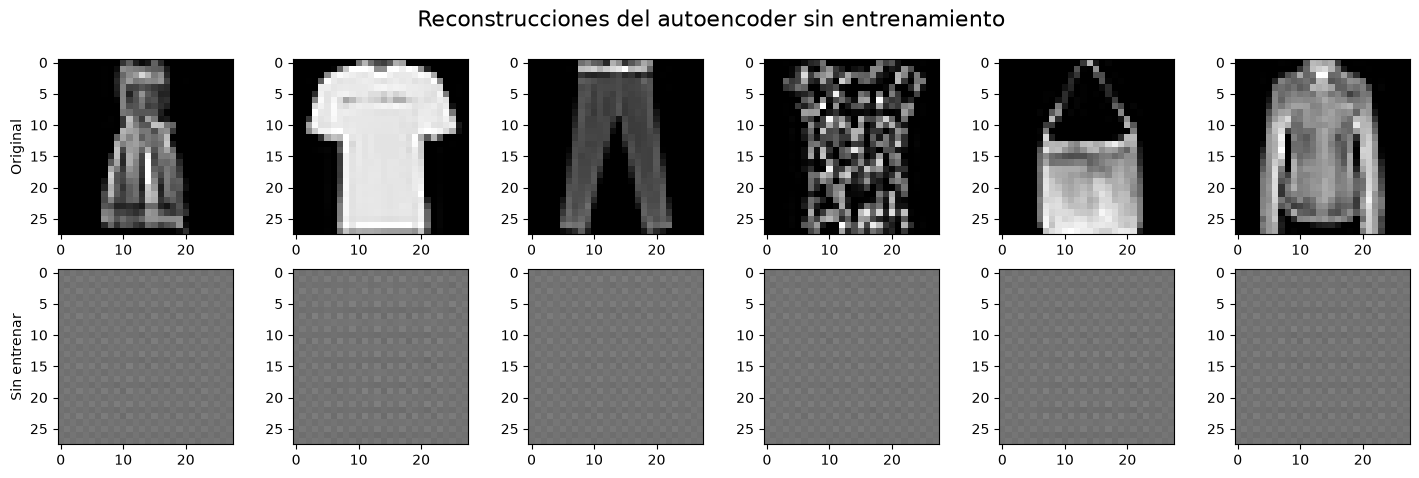

In [82]:
@torch.no_grad()
def show_untrained_reconstructions(model, data_loader, device, n=6):
    model.eval()

    images, _ = next(iter(data_loader))
    images = images[:n].to(device)

    reconstructions = model(images)

    images = images.cpu()
    reconstructions = reconstructions.cpu()

    fig, axes = plt.subplots(2, n, figsize=(3 * n, 5))

    for i in range(n):
        axes[0, i].imshow(images[i].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[1, i].imshow(reconstructions[i].squeeze(), cmap="gray", vmin=0, vmax=1)

    axes[0, 0].set_ylabel("Original")
    axes[1, 0].set_ylabel("Sin entrenar")

    fig.suptitle("Reconstrucciones del autoencoder sin entrenamiento", fontsize=16)

    fig.subplots_adjust(wspace=0.08, hspace=0.2)
    plt.show()


show_untrained_reconstructions(model, validation_loader, device)

# 9. Entrenamiento

## 9.1 A tener en cuenta para obtener el mejor modelo

**¿Cómo sabemos que estaremos obteniendo el mejor modelo a partir de ahora?**
A partir de ahora voy a trackear los resultados en una carpeta para `checkpoints`.

Entonces guardaré el modelo en base a la mejor validación con la función `save_model` 

In [12]:
def save_model(model, filename):
    checkpoint_dir = Path("checkpoints")
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    path = checkpoint_dir / filename

    torch.save(model.state_dict(), path)

In [ ]:
EPOCHS = 20

history = {
    "train_loss": [],
    "valid_loss": []
}

best_valid_loss = float("inf")
best_epoch = 0


for epoch in range(EPOCHS):
    train_one_epoch(
        model, train_loader, loss_fn, optimizer, device
    )

    train_loss = evaluate(
        model, train_loader, loss_fn, device
    )

    valid_loss = evaluate(
        model, validation_loader, loss_fn, device
    )

    history["train_loss"].append(train_loss)
    history["valid_loss"].append(valid_loss)

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        best_epoch = epoch + 1

        save_model(model, "baseline_best.pth")
        print(f"* Nuevo mejor modelo guardado en la época {best_epoch}")

    print("_"*70)
    print(f"ÉPOCA N°{epoch+1}/{EPOCHS}:")
    print(f"\t  TRAIN MSE:  {train_loss:.6f} | VALID MSE: {valid_loss:.6f}")

print("_"*70)
print("DETALLES FINALES:")
print(f"\t *Mejor época: {best_epoch}")
print(f"\t *Mejor MSE de validación: {best_valid_loss:.6f}")

______________________________________________________________________
ÉPOCA N°1/20:
	  TRAIN MSE:  0.005998 | VALID MSE: 0.005948
______________________________________________________________________
ÉPOCA N°2/20:
	  TRAIN MSE:  0.003199 | VALID MSE: 0.003171
______________________________________________________________________
ÉPOCA N°3/20:
	  TRAIN MSE:  0.002279 | VALID MSE: 0.002259
______________________________________________________________________
ÉPOCA N°4/20:
	  TRAIN MSE:  0.001812 | VALID MSE: 0.001796
______________________________________________________________________
ÉPOCA N°5/20:
	  TRAIN MSE:  0.001583 | VALID MSE: 0.001569
______________________________________________________________________
ÉPOCA N°6/20:
	  TRAIN MSE:  0.001331 | VALID MSE: 0.001319
______________________________________________________________________
ÉPOCA N°7/20:
	  TRAIN MSE:  0.001185 | VALID MSE: 0.001174
______________________________________________________________________
ÉPOCA N°8/20

# 9.2 Graficar los resultados

In [13]:

def view_results(history, model_name="Baseline"):
    train_loss_history = history["train_loss"]
    valid_loss_history = history["valid_loss"]

    epochs = range(1, len(train_loss_history) + 1)

    # Paleta Magma Night
    fondo = "#252037"
    fondo_axes = "#322940"
    titulo = "#F4B7DB"
    texto = "#E9DDED"
    grilla = "#645574"

    color_train = "#E879B9"
    color_valid = "#F5A36C"

    fig, ax = plt.subplots(
        figsize=(10, 5),
        layout="constrained",
        facecolor=fondo
    )

    ax.plot(
        epochs,
        train_loss_history,
        marker="o",
        markersize=6,
        linewidth=3.5,
        linestyle="-",
        label="Entrenamiento",
        color=color_train,
        alpha=0.80,
        zorder=3
    )

    ax.plot(
        epochs,
        valid_loss_history,
        marker="s",
        markersize=5,
        linewidth=2.5,
        linestyle="--",
        label="Validación",
        color=color_valid,
        alpha=0.95,
        zorder=4
    )

    ax.set_facecolor(fondo_axes)
    ax.set_title("Pérdida de reconstrucción", color=texto)
    ax.set_xlabel("Época", color=texto)
    ax.set_ylabel("MSE", color=texto)

    ax.set_xticks(list(epochs))
    ax.tick_params(colors=texto)
    ax.grid(color=grilla, alpha=0.35)

    for borde in ax.spines.values():
        borde.set_color(grilla)

    ax.legend(
        facecolor=fondo_axes,
        edgecolor=grilla,
        labelcolor=texto
    )

    fig.suptitle(
        f"Autoencoder convolucional - {model_name}",
        color=titulo,
        fontsize=15,
        fontweight="bold"
    )

    plt.show()


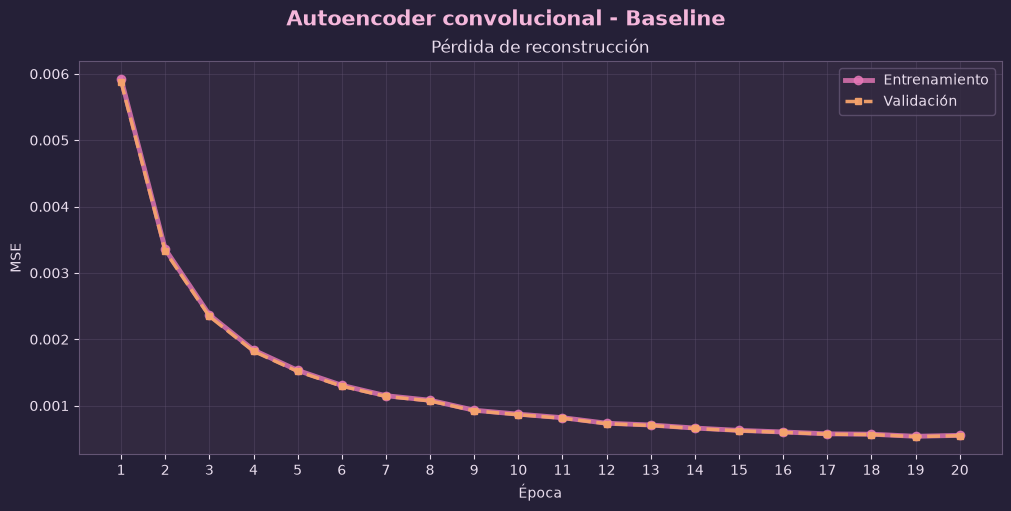

In [104]:
view_results(history, "Baseline")

# 10. Visualizamos las reconstrucciones 

## 10.1 Antes, cargamos el modelo con el mejor resultado de validación en cuanto a las épocas

In [17]:
baseline_model = ConvAutoencoder().to(device)
checkpoint = Path("checkpoints/baseline_best.pth")

baseline_model.load_state_dict(
    torch.load(
        checkpoint,
        map_location=device,
        weights_only=True
    )
)

baseline_model.eval()

print("Modelo cargado correctamente")

valid_loss = evaluate(
    baseline_model,
    validation_loader,
    loss_fn,
    device
)

print(f"MSE de validación: {valid_loss:.6f}")

Modelo cargado correctamente
MSE de validación: 0.000533


In [24]:
@torch.no_grad()
def show_reconstructions(model, data_loader, device, name_model, n=6, indexes=None):
    model.eval()

    dataset = data_loader.dataset

    if indexes is None:
        indexes = torch.randperm(len(dataset))[:n].tolist()
    else:
        n = len(indexes)

    # Recuperar las imágenes seleccionadas
    images = torch.stack([
        dataset[idx][0] for idx in indexes
    ]).to(device)

    reconstructions = model(images)

    images = images.cpu()
    reconstructions = reconstructions.cpu()

    fondo = "#252037"
    texto = "#E9DDED"
    titulo = "#F4B7DB"

    fig, axes = plt.subplots(
        2, n,
        figsize=(3 * n, 5),
        facecolor=fondo
    )

    for i in range(n):
        axes[0, i].imshow(
            images[i].squeeze(),
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[1, i].imshow(
            reconstructions[i].squeeze(),
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[0, i].set_xticks([])
        axes[0, i].set_yticks([])

        axes[1, i].set_xticks([])
        axes[1, i].set_yticks([])

    axes[0, 0].set_ylabel("Original", color=texto)
    axes[1, 0].set_ylabel("Reconstrucción", color=texto)

    fig.suptitle(
        f"Reconstrucciones del autoencoder convolucional - {name_model}",
        color=titulo,
        fontsize=15,
        fontweight="bold"
    )

    fig.subplots_adjust(
        wspace=0.08,
        hspace=0.12,
        top=0.85
    )

    plt.show()

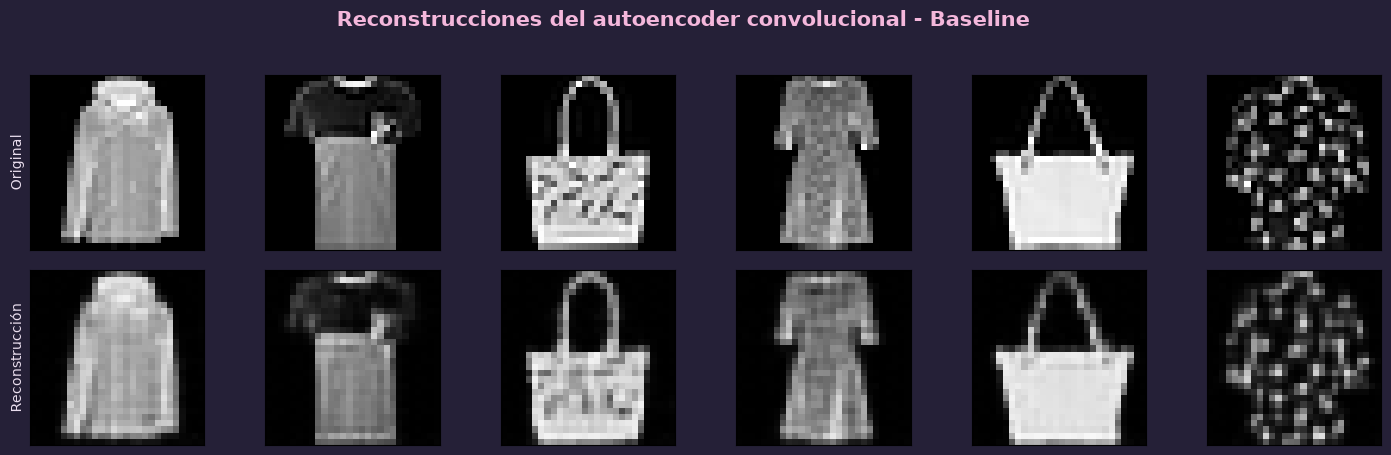

In [26]:
show_reconstructions(model, validation_loader, device, "Baseline")

### Consideración importante de los resultados obtenidos
El bottleneck del baseline contiene 1568 valores, mientras que la imagen original contiene 784 píxeles.

Por eso, aunque el modelo aprende una representación con menor resolución espacial, no está obligado a comprimir la cantidad total de información representada.

# 11. Experimentos con diferentes hiperparámetros
Se propone aumentar la cantidad de canales de las capas convolucionales para analizar el efecto de una mayor capacidad de representación sobre el error de reconstrucción.

## 11.1.1 Primer Experimento: Aumentamos el mapa de características

In [13]:
class ConvAutoencoderV2(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat

## 11.1.2 Verificamos la arquitectura antes de entrenar

In [ ]:

model_example = ConvAutoencoderV2().to(device)

images, _ = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    z = model_example.encoder(images)
    reconstructions = model_example(images)

print("Entrada:", images.shape)
print("Representación latente:", z.shape)
print("Elementos por imagen:", z[0].numel())
print("Reconstrucción:", reconstructions.shape)

Entrada: torch.Size([128, 1, 28, 28])
Representación latente: torch.Size([128, 64, 7, 7])
Reconstrucción: torch.Size([128, 1, 28, 28])


## 11.1.3 Creamos el nuevo modelo y entrenamos

In [21]:
torch.manual_seed(SEED)

model_v2 = ConvAutoencoderV2().to(device)

loss_fn_v2 = nn.MSELoss()

optimizer_v2 = torch.optim.Adam(model_v2.parameters(), lr=0.001)

EPOCHS = 20

history_model_v2 = {
    "train_loss": [],
    "valid_loss": []
}

best_valid_loss_v2 = float("inf")
best_epoch_v2 = 0


for epoch in range(EPOCHS):
    train_one_epoch(
        model_v2, train_loader, loss_fn_v2, optimizer_v2, device
    )

    train_loss = evaluate(
        model_v2, train_loader, loss_fn_v2, device
    )

    valid_loss = evaluate(
        model_v2, validation_loader, loss_fn_v2, device
    )

    history_model_v2["train_loss"].append(train_loss)
    history_model_v2["valid_loss"].append(valid_loss)

    if valid_loss < best_valid_loss_v2:
        best_valid_loss_v2 = valid_loss
        best_epoch_v2 = epoch + 1

        save_model(model_v2, "autoencoder_v2_best.pth")
        print(f"* Nuevo mejor modelo guardado en la época {best_epoch_v2}")

    print("_"*70)
    print(f"ÉPOCA N°{epoch+1}/{EPOCHS}:")
    print(f"\t  TRAIN MSE:  {train_loss:.6f} | VALID MSE: {valid_loss:.6f}")

print("_"*70)
print("DETALLES FINALES:")
print(f"\t *Mejor época: {best_epoch_v2}")
print(f"\t *Mejor MSE de validación: {best_valid_loss_v2:.6f}")

* Nuevo mejor modelo guardado en la época 1
______________________________________________________________________
ÉPOCA N°1/20:
	  TRAIN MSE:  0.002316 | VALID MSE: 0.002297
* Nuevo mejor modelo guardado en la época 2
______________________________________________________________________
ÉPOCA N°2/20:
	  TRAIN MSE:  0.001394 | VALID MSE: 0.001384
* Nuevo mejor modelo guardado en la época 3
______________________________________________________________________
ÉPOCA N°3/20:
	  TRAIN MSE:  0.000973 | VALID MSE: 0.000966
* Nuevo mejor modelo guardado en la época 4
______________________________________________________________________
ÉPOCA N°4/20:
	  TRAIN MSE:  0.000780 | VALID MSE: 0.000773
* Nuevo mejor modelo guardado en la época 5
______________________________________________________________________
ÉPOCA N°5/20:
	  TRAIN MSE:  0.000709 | VALID MSE: 0.000703
* Nuevo mejor modelo guardado en la época 6
______________________________________________________________________
ÉPOCA N°6/

## 11.2.1 Segundo experimento: Representación más compacta
Reducir el tamaño del bottleneck podría aumentar el error de reconstrucción, pero obligaría al encoder a trabajar con una representación más compacta. No podemos anticipar si esa representación resultará más útil para clasificación.

In [14]:
class ConvAutoencoderV3(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(16, 8, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(8, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

## 11.2.2 Verificamos la arquitectura antes de entrenar

In [30]:
model_example = ConvAutoencoderV3().to(device)

images, _ = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    z = model_example.encoder(images)
    reconstructions = model_example(images)

print("Entrada:", images.shape)
print("Representación latente:", z.shape)
print("Elementos por imagen:", z[0].numel())
print("Reconstrucción:", reconstructions.shape)

Entrada: torch.Size([128, 1, 28, 28])
Representación latente: torch.Size([128, 8, 7, 7])
Elementos por imagen: 392
Reconstrucción: torch.Size([128, 1, 28, 28])


## 11.2.3 Creamos el nuevo modelo y entrenamos

In [31]:
torch.manual_seed(SEED)

model_v3 = ConvAutoencoderV3().to(device)

loss_fn_v3 = nn.MSELoss()

optimizer_v3 = torch.optim.Adam(model_v3.parameters(), lr=0.001)

EPOCHS = 20

history_model_v3 = {
    "train_loss": [],
    "valid_loss": []
}

best_valid_loss_v3 = float("inf")
best_epoch_v3 = 0


for epoch in range(EPOCHS):
    train_one_epoch(
        model_v3, train_loader, loss_fn_v3, optimizer_v3, device
    )

    train_loss = evaluate(
        model_v3, train_loader, loss_fn_v3, device
    )

    valid_loss = evaluate(
        model_v3, validation_loader, loss_fn_v3, device
    )

    history_model_v3["train_loss"].append(train_loss)
    history_model_v3["valid_loss"].append(valid_loss)

    if valid_loss < best_valid_loss_v3:
        best_valid_loss_v3 = valid_loss
        best_epoch_v3 = epoch + 1

        save_model(model_v3, "autoencoder_v3_best.pth")
        print(f"* Nuevo mejor modelo guardado en la época {best_epoch_v3}")

    print("_"*70)
    print(f"ÉPOCA N°{epoch+1}/{EPOCHS}:")
    print(f"\t  TRAIN MSE:  {train_loss:.6f} | VALID MSE: {valid_loss:.6f}")

print("_"*70)
print("DETALLES FINALES:")
print(f"\t *Mejor época: {best_epoch_v3}")
print(f"\t *Mejor MSE de validación: {best_valid_loss_v3:.6f}")

* Nuevo mejor modelo guardado en la época 1
______________________________________________________________________
ÉPOCA N°1/20:
	  TRAIN MSE:  0.009702 | VALID MSE: 0.009633
* Nuevo mejor modelo guardado en la época 2
______________________________________________________________________
ÉPOCA N°2/20:
	  TRAIN MSE:  0.006428 | VALID MSE: 0.006378
* Nuevo mejor modelo guardado en la época 3
______________________________________________________________________
ÉPOCA N°3/20:
	  TRAIN MSE:  0.005287 | VALID MSE: 0.005245
* Nuevo mejor modelo guardado en la época 4
______________________________________________________________________
ÉPOCA N°4/20:
	  TRAIN MSE:  0.004607 | VALID MSE: 0.004569
* Nuevo mejor modelo guardado en la época 5
______________________________________________________________________
ÉPOCA N°5/20:
	  TRAIN MSE:  0.004245 | VALID MSE: 0.004208
* Nuevo mejor modelo guardado en la época 6
______________________________________________________________________
ÉPOCA N°6/

# 11.3 Resultados de los experimentos

## 11.3.1 Recuperamos los historiales guardados en archivos

In [15]:
baseline_model = ConvAutoencoder().to(device)
baseline_model.load_state_dict(
    torch.load(
        "checkpoints/baseline_best.pth",
        map_location=device,
        weights_only=True
    )
)

model_v2 = ConvAutoencoderV2().to(device)
model_v2.load_state_dict(
    torch.load(
        "checkpoints/autoencoder_v2_best.pth",
        map_location=device,
        weights_only=True
    )
)

model_v3 = ConvAutoencoderV3().to(device)
model_v3.load_state_dict(
    torch.load(
        "checkpoints/autoencoder_v3_best.pth",
        map_location=device,
        weights_only=True
    )
)


models = {
    "Baseline": baseline_model,
    "Modelo V2": model_v2,
    "Modelo V3": model_v3
}

experiments = {}

for name, model in models.items():
    model.eval()

    train_mse = evaluate(
        model, train_loader, nn.MSELoss(), device
    )

    valid_mse = evaluate(
        model, validation_loader, nn.MSELoss(), device
    )

    experiments[name] = {
        "train_mse": train_mse,
        "best_valid_loss": valid_mse,
        "parameters": sum(
            p.numel() for p in model.parameters()
        )
    }

    print(
        f"{name}: "
        f"TRAIN MSE = {train_mse:.6f} | "
        f"VALID MSE = {valid_mse:.6f}"
    )

Baseline: TRAIN MSE = 0.000538 | VALID MSE = 0.000533
Modelo V2: TRAIN MSE = 0.000307 | VALID MSE = 0.000304
Modelo V3: TRAIN MSE = 0.003032 | VALID MSE = 0.003004


## 11.3.2 Definicion de funciones para comparar los resultados

In [25]:
def compare_autoencoders(experiments):
    names = list(experiments.keys())

    train_losses = [
        exp["train_mse"]
        for exp in experiments.values()
    ]

    valid_losses = [
        exp["best_valid_loss"]
        for exp in experiments.values()
    ]

    # Paleta Magma Night
    fondo = "#252037"
    fondo_axes = "#322940"
    titulo = "#F4B7DB"
    texto = "#E9DDED"
    grilla = "#645574"

    color_train = "#E879B9"
    color_valid = "#F5A36C"

    x = np.arange(len(names))
    width = 0.35

    fig, ax = plt.subplots(
        figsize=(10, 5),
        layout="constrained",
        facecolor=fondo
    )

    ax.set_facecolor(fondo_axes)

    bars_train = ax.bar(
        x - width / 2,
        train_losses,
        width,
        label="Entrenamiento",
        color=color_train,
        alpha=0.85
    )

    bars_valid = ax.bar(
        x + width / 2,
        valid_losses,
        width,
        label="Validación",
        color=color_valid,
        alpha=0.90
    )

    # Etiquetas sobre las barras
    for bars in (bars_train, bars_valid):
        for bar in bars:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height(),
                f"{bar.get_height():.6f}",
                ha="center",
                va="bottom",
                color=texto,
                fontsize=9
            )

    ax.set_title("Comparación de autoencoders convolucionales", color=texto)
    ax.set_xlabel("Modelo", color=texto)
    ax.set_ylabel("MSE", color=texto)

    ax.set_xticks(x)
    ax.set_xticklabels(names, color=texto)

    ax.tick_params(colors=texto)
    ax.grid(axis="y", color=grilla, alpha=0.35)

    for borde in ax.spines.values():
        borde.set_color(grilla)

    ax.legend(
        facecolor=fondo_axes,
        edgecolor=grilla,
        labelcolor=texto
    )

    fig.suptitle(
        "Comparación final de modelos",
        color=titulo,
        fontsize=15,
        fontweight="bold"
    )

    plt.savefig(
        "figures/autoencoders_comparison.pdf",
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()

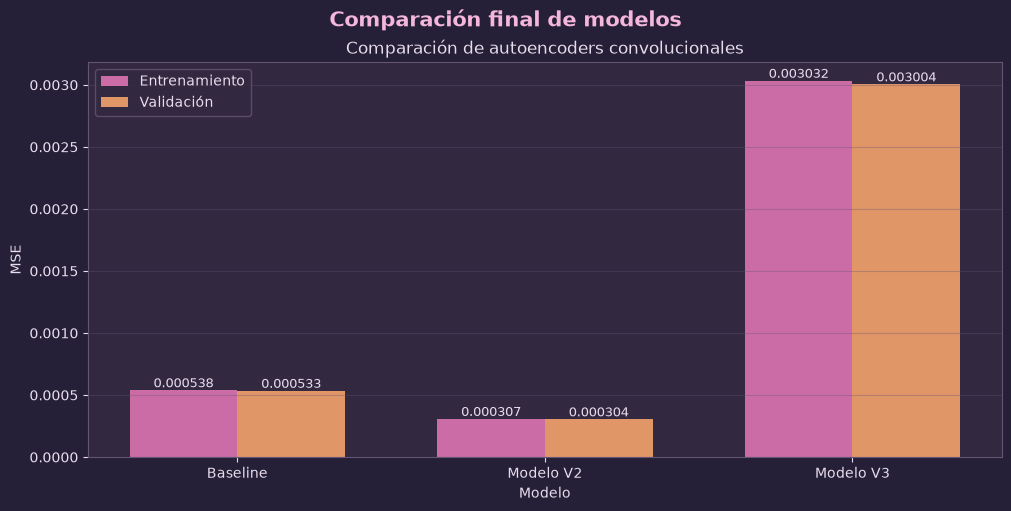

In [26]:
compare_autoencoders(experiments)

In [30]:
def plot_experiments(experiments):
    available = {
        name: exp
        for name, exp in experiments.items()
        if "history" in exp and exp["history"] is not None
    }

    if not available:
        print("No hay historiales de entrenamiento disponibles.")
        return

    # Paleta Magma Night
    fondo = "#252037"
    fondo_axes = "#322940"
    titulo = "#F4B7DB"
    texto = "#E9DDED"
    grilla = "#645574"

    color_train = "#E879B9"
    color_valid = "#F5A36C"

    fig, axes = plt.subplots(
        1,
        len(available),
        figsize=(6 * len(available), 4.8),
        sharey=True,
        squeeze=False,
        layout="constrained",
        facecolor=fondo
    )

    for ax, (name, experiment) in zip(axes[0], available.items()):
        history = experiment["history"]

        train_loss_history = history["train_loss"]
        valid_loss_history = history["valid_loss"]

        epochs = range(1, len(train_loss_history) + 1)

        ax.plot(
            epochs,
            train_loss_history,
            marker="o",
            markersize=5,
            linewidth=3,
            linestyle="-",
            label="Entrenamiento",
            color=color_train,
            alpha=0.80,
            zorder=3
        )

        ax.plot(
            epochs,
            valid_loss_history,
            marker="s",
            markersize=4.5,
            linewidth=2.3,
            linestyle="--",
            label="Validación",
            color=color_valid,
            alpha=0.95,
            zorder=4
        )

        ax.set_facecolor(fondo_axes)
        ax.set_title(name, color=texto, fontsize=12)
        ax.set_xlabel("Época", color=texto)
        ax.set_ylabel("MSE", color=texto)

        ax.set_xticks(list(epochs))
        ax.tick_params(colors=texto)
        ax.grid(color=grilla, alpha=0.35)

        for borde in ax.spines.values():
            borde.set_color(grilla)

        ax.legend(
            facecolor=fondo_axes,
            edgecolor=grilla,
            labelcolor=texto
        )

    fig.suptitle(
        "Curvas de entrenamiento de autoencoders convolucionales",
        color=titulo,
        fontsize=15,
        fontweight="bold"
    )

    plt.savefig(
        "figures/autoencoders_curves.pdf",
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()

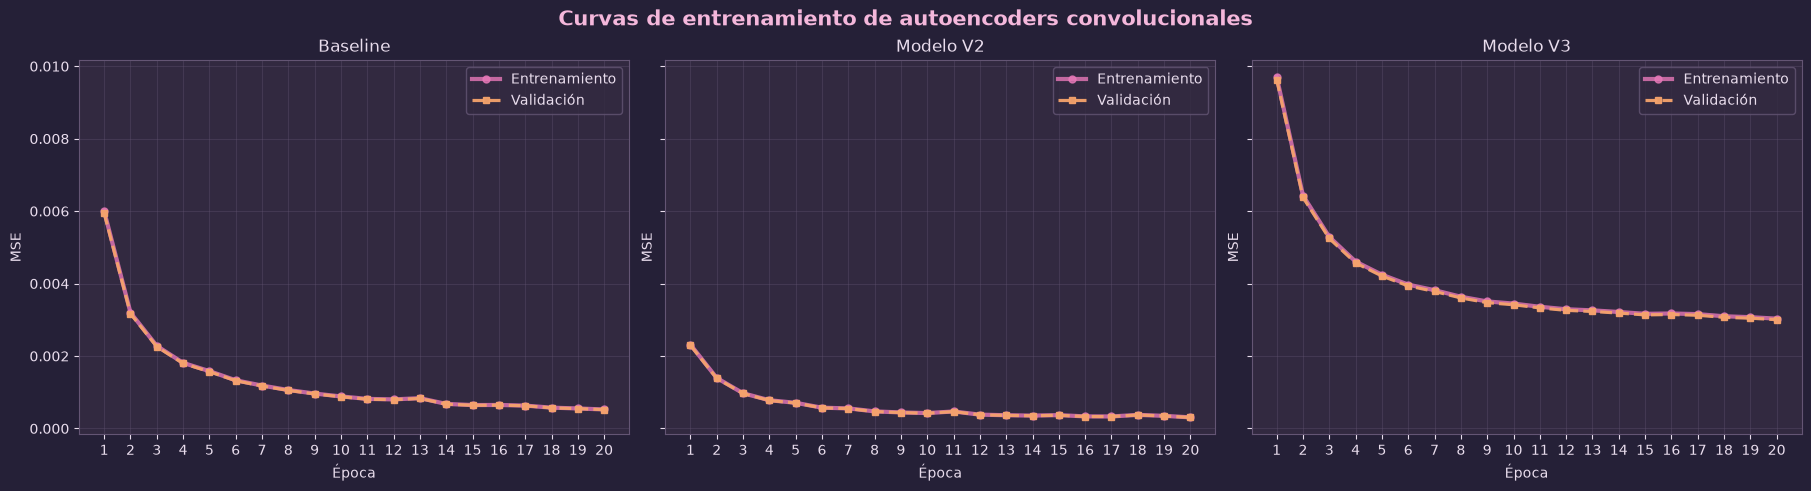

In [35]:
with open(
    Path("data/history/autoencoders_historiales.json"),
    "r",
    encoding="utf-8"
) as f:
    experiments = json.load(f)

plot_experiments(experiments)

## 11.3.3 Comparación de clases que tengan muchas características

In [ ]:
def select_detailed_images(data_loader, classes, top_k=20):
    dataset = data_loader.dataset

    selected_index = []

    for cls in classes:
        scores = []

        for idx in range(len(dataset)):
            image, label = dataset[idx]

            if int(label) != cls:
                continue

            # Variación horizontal y vertical
            dx = torch.abs(image[:, :, 1:] - image[:, :, :-1]).mean()
            dy = torch.abs(image[:, 1:, :] - image[:, :-1, :]).mean()

            score = (dx + dy).item()

            scores.append((score, idx))

        # Ordenar de mayor a menor detalle
        scores.sort(reverse=True)

        # Obtener los índices de las imágenes más detalladas
        candidates = [idx for _, idx in scores[:top_k]]

        # Seleccionar aleatoriamente una de ellas
        random_index = torch.randint(len(candidates), (1,)).item()

        selected_index.append(candidates[random_index])

    return selected_index

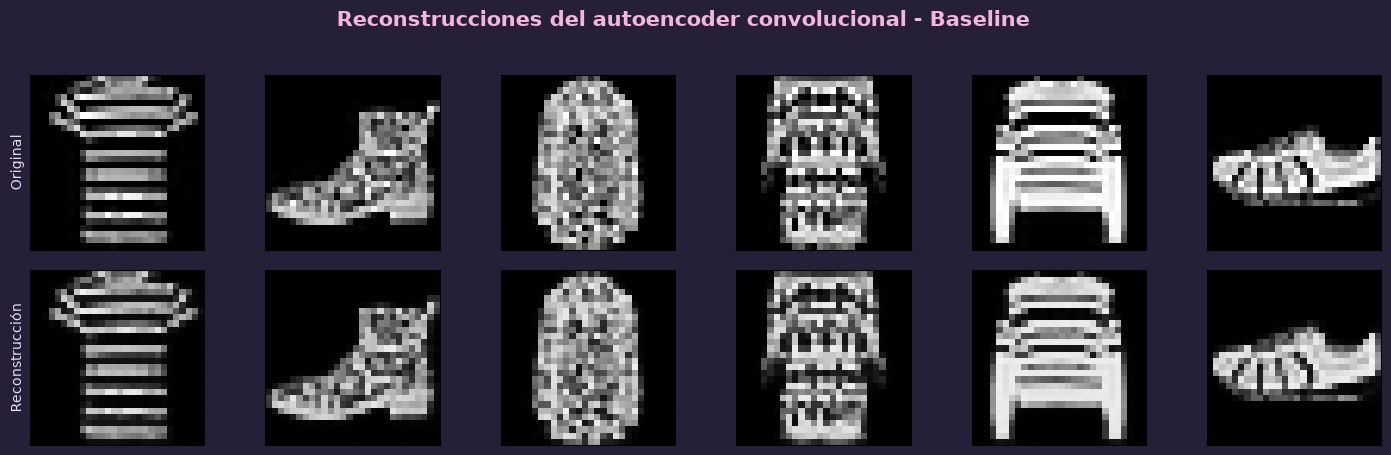

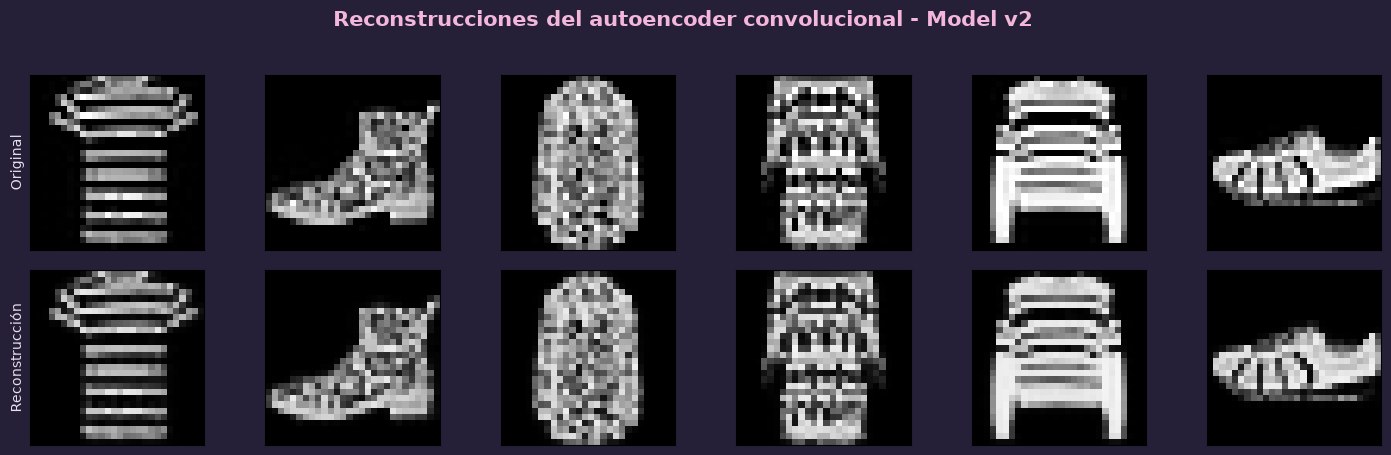

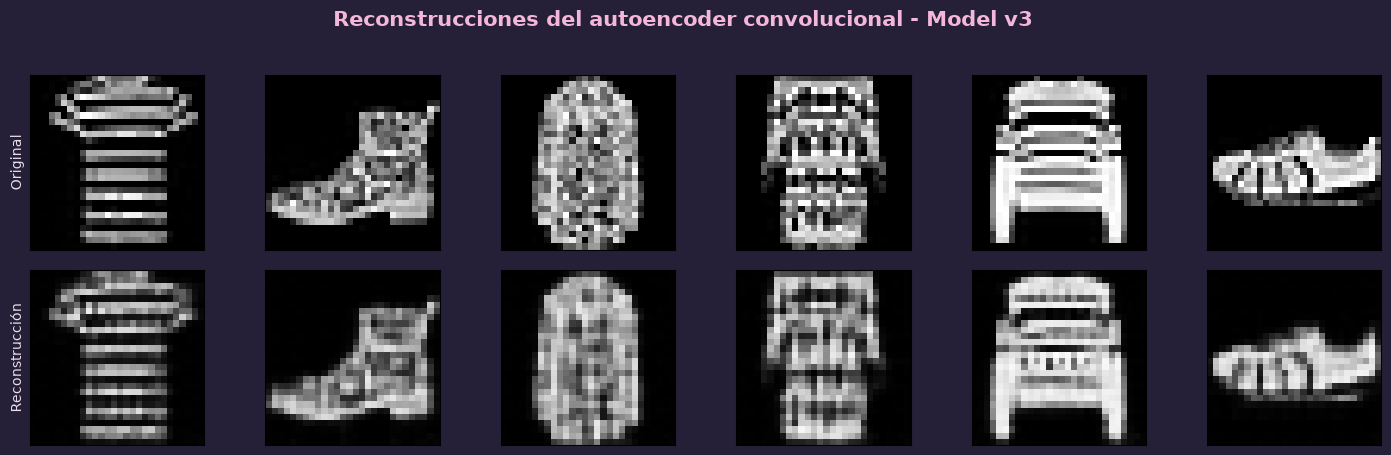

In [36]:
classes = [0, 9, 4, 3, 2, 7]

indexes = select_detailed_images(validation_loader, classes, top_k=20)

show_reconstructions(baseline_model, validation_loader, device, name_model="Baseline", indexes=indexes)
show_reconstructions(model_v2, validation_loader, device, name_model="Model v2", indexes=indexes)
show_reconstructions(model_v3, validation_loader, device, name_model="Model v3", indexes=indexes)

---

# Parte dos: Clasificación de imágenes

Siguiendo lo que indica las especificaciones del trabajo realizaremos una comparación con 4 modelos:
- Modelo con Pre-Entrenado congelado: inicialización de encoder con sus respectivos pesos y NO se entrena.
- Modelo desde cero: inicialización de encoder aleatorio y SI se entrena.
- Modelo Fine Tuning: inicialización de enconder con pesos del modelo V2 y SI se entrena.
- Modelo Aleatorio congelado: inicialización de encoder aleatorio y NO se entrena.

Estas comparaciones nos permitirá investigar si el pre-entrenamiento mediante reconstrucción aporta alguna ventaja a la clasificación.

In [39]:
from copy import deepcopy

# 1. Implementamos el clasificador Pre-Entrenado Congelado

In [37]:
class ConvClassifier(nn.Module):
    def __init__(self, encoder):
        super().__init__()

        self.encoder = encoder

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 10)
        )

    def forward(self, x):
        x = self.encoder(x)
        return self.classifier(x)

In [44]:
classifier_pretrained_frozen = ConvClassifier(encoder=deepcopy(model_v2.encoder)).to(device)

# Congelar el encoder y verificar los parámetros
for name, param in classifier_pretrained_frozen.named_parameters():
    if name.startswith("encoder."):
        param.requires_grad = False

    print(f"{name}: {param.requires_grad}")

encoder.0.weight: False
encoder.0.bias: False
encoder.2.weight: False
encoder.2.bias: False
classifier.1.weight: True
classifier.1.bias: True


# 2. Función pérdida

In [45]:
loss_fn = nn.CrossEntropyLoss()

# 3. Definimos el optimizador

In [46]:
LEARNING_RATE = 0.001

optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        classifier_pretrained_frozen.parameters()
    ),
    lr=LEARNING_RATE
)

# 4. Entrenamiento y evaluación 

In [47]:
def train_classifier_one_epoch(model, data_loader, loss_fn, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total

In [ ]:
@torch.no_grad()
def evaluate(model, data_loader, loss_fn, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total